# West Coast submarine cable observatory maps

Bathymetry-styled maps of Morro Bay DAS, MARS, and the OOI Regional Cabled Array.

**Data provenance:**
- Morro Bay cable route: surveyed, NOAA ENC (`cable_geo.py`, already used throughout this project).
- OOI Regional Cabled Array node positions: real coordinates from OOI's public
  asset-management deployment records (`github.com/oceanobservatories/asset-management`).
- MARS node: real coordinate (36.713N, 122.186W, 891 m depth) from MBARI/IQOE.
- Cable paths between nodes, and both shore stations (Pacific City OR, Moss Landing CA),
  are straight-line approximations between real points -- not surveyed routes.
- Bathymetry: NOAA NCEI ETOPO 2022, 15 arcsec, fetched via ERDDAP
  (`coastwatch.pfeg.noaa.gov/erddap/griddap/ETOPO_2022_v1_15s`), cached locally in
  `localization_results/data/`.


In [9]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.ticker import FuncFormatter

REPO = Path("/home/sjuber/interferometry-for-orcas")
sys.path.insert(0, str(REPO / "scripts"))
DATADIR = REPO / "results" / "localization_results" / "data"
FIGDIR = REPO / "results" / "localization_results" / "figures"

from cable_geo import _load_cable

plt.rcParams.update({
    "font.size": 18,
    "axes.labelsize": 19,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 15,
})
%matplotlib inline

In [10]:
# real cable / node coordinates -- see provenance notes above
mb_cable = _load_cable()
mb_lon, mb_lat = mb_cable["coords"][:, 0], mb_cable["coords"][:, 1]

mars_lon = np.array([-121.789, -122.186])   # Moss Landing (shore) -> MARS node
mars_lat = np.array([36.802, 36.713])
mars_node = (-122.186, 36.713)

ooi_shore = (-123.959, 45.208)              # Pacific City, OR (approx. shore station)
ooi_slope_base = (-125.397, 44.519)
ooi_hydrate_ridge = (-125.147, 44.570)
ooi_axial_base = (-129.757, 45.827)
ooi_caldera = [(-130.014, 45.934), (-130.009, 45.955), (-129.980, 45.950), (-129.979, 45.926)]
ooi_margin_branch_lon = [ooi_shore[0], ooi_slope_base[0], ooi_hydrate_ridge[0]]
ooi_margin_branch_lat = [ooi_shore[1], ooi_slope_base[1], ooi_hydrate_ridge[1]]
ooi_axial_branch_lon = [ooi_shore[0], ooi_axial_base[0]] + [c[0] for c in ooi_caldera]
ooi_axial_branch_lat = [ooi_shore[1], ooi_axial_base[1]] + [c[1] for c in ooi_caldera]

## Bathymetry helpers

Ocean is colored by depth (sequential colormap); land is drawn as a flat color and
does not appear in the colorbar. Colorbar tick labels show positive magnitudes
(depth below sea level), via `FuncFormatter`.


In [31]:
LAND_COLOR = "#c2a876"
_abs_fmt = FuncFormatter(lambda x, pos: f"{abs(x):.0f}")

def ocean_cmap():
    ocean_colors = ["#d1e5f0", "#67a9cf", "#2166ac", "#08306b"]
    return LinearSegmentedColormap.from_list("ocean_depth", ocean_colors)


def plot_bathy(ax, lon, lat, Z, fig):
    Z_ocean = np.ma.masked_where(Z > 0, Z)
    Z_land = np.ma.masked_where(Z <= 0, np.ones_like(Z))
    im = ax.pcolormesh(lon, lat, Z_ocean, cmap=ocean_cmap(), vmin=np.nanmin(Z), vmax=0, shading="auto")
    ax.pcolormesh(lon, lat, Z_land, cmap=ListedColormap([LAND_COLOR]), shading="auto")
    cbar = fig.colorbar(im, ax=ax, pad=0.015, fraction=0.04)
    cbar.ax.yaxis.set_major_formatter(_abs_fmt)
    cbar.set_label("Depth [m]")
    return cbar


def load_bathy(path):
    df = pd.read_csv(path, skiprows=[1])
    lat_u = np.sort(df["latitude"].unique())
    lon_u = np.sort(df["longitude"].unique())
    Z = df.pivot(index="latitude", columns="longitude", values="z").reindex(index=lat_u, columns=lon_u).values
    return lon_u, lat_u, Z

## Map 1: full West Coast overview

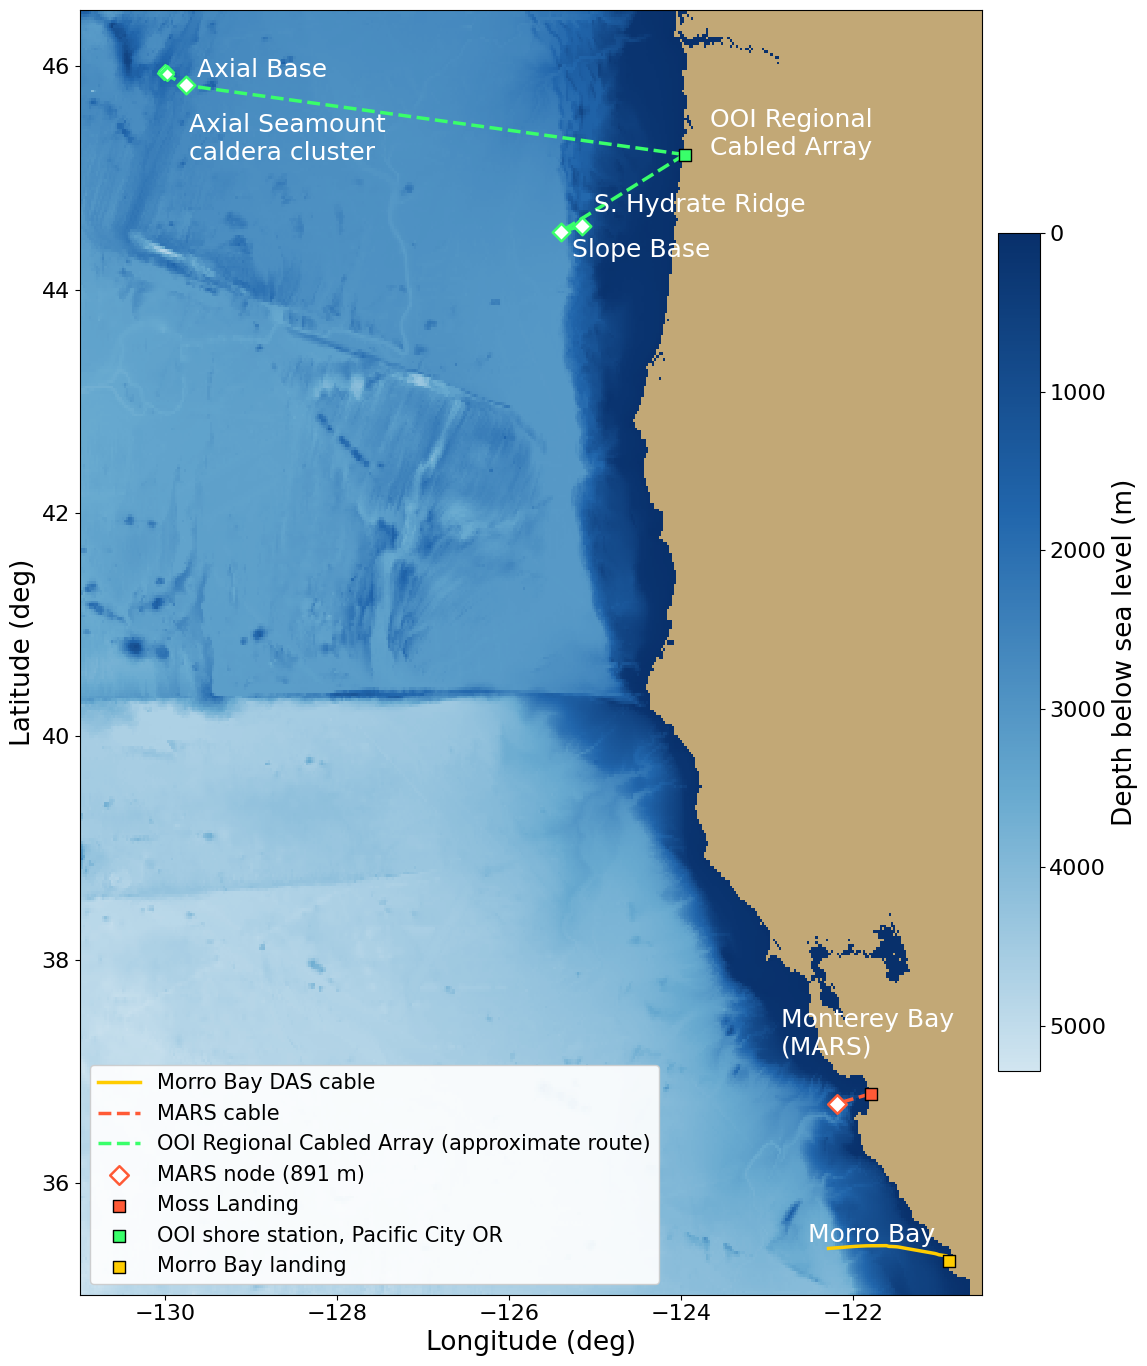

In [12]:
lon_u, lat_u, Z = load_bathy(DATADIR / "bathymetry_westcoast_15s_subsampled.csv")

fig, ax = plt.subplots(figsize=(12, 14))
plot_bathy(ax, lon_u, lat_u, Z, fig)

ax.plot(mb_lon, mb_lat, color="#ffcc00", lw=2.5, label="Morro Bay DAS cable")
ax.plot(mars_lon, mars_lat, color="#ff5a36", lw=2.5, ls="--", label="MARS cable")
ax.plot(ooi_margin_branch_lon, ooi_margin_branch_lat, color="#39ff6a", lw=2.5, ls="--",
        label="OOI Regional Cabled Array (approximate route)")
ax.plot(ooi_axial_branch_lon, ooi_axial_branch_lat, color="#39ff6a", lw=2.5, ls="--")

ax.scatter(*mars_node, marker="D", s=90, color="white", edgecolor="#ff5a36", lw=1.8, zorder=5, label="MARS node (891 m)")
ax.scatter(mars_lon[0], mars_lat[0], marker="s", s=65, color="#ff5a36", edgecolor="k", zorder=5, label="Moss Landing")

ooi_nodes = [("Slope Base", ooi_slope_base), ("S. Hydrate Ridge", ooi_hydrate_ridge), ("Axial Base", ooi_axial_base)]
ooi_label_offsets = {"Slope Base": (8, -18), "S. Hydrate Ridge": (8, 10), "Axial Base": (8, 6)}
for name, (lo, la) in ooi_nodes:
    ax.scatter(lo, la, marker="D", s=80, color="white", edgecolor="#39ff6a", lw=1.8, zorder=5)
    ax.annotate(name, (lo, la), textcoords="offset points", xytext=ooi_label_offsets[name], color="white")
for lo, la in ooi_caldera:
    ax.scatter(lo, la, marker="D", s=45, color="white", edgecolor="#39ff6a", lw=1.5, zorder=5)
ax.annotate("Axial Seamount\ncaldera cluster", ooi_caldera[0], textcoords="offset points", xytext=(18, -62),
            color="white")
ax.scatter(*ooi_shore, marker="s", s=65, color="#39ff6a", edgecolor="k", zorder=5, label="OOI shore station, Pacific City OR")

ax.scatter(mb_lon[0], mb_lat[0], marker="s", s=65, color="#ffcc00", edgecolor="k", zorder=5, label="Morro Bay landing")
ax.annotate("Morro Bay", (mb_lon[0], mb_lat[0]), textcoords="offset points", xytext=(-10, 14),
            ha="right", color="white")
ax.annotate("Monterey Bay\n(MARS)", mars_node, textcoords="offset points", xytext=(-40, 35), color="white")
ax.annotate("OOI Regional\nCabled Array", (ooi_shore[0] + 0.3, ooi_shore[1]), color="white")

ax.set_xlim(lon_u.min(), lon_u.max())
ax.set_ylim(lat_u.min(), lat_u.max())
ax.set_xlabel("Longitude (deg)")
ax.set_ylabel("Latitude (deg)")
ax.legend(loc="lower left", framealpha=0.92)
ax.set_aspect(1.3)
plt.tight_layout()
plt.savefig(FIGDIR / "21_westcoast_cable_map.png", dpi=150, bbox_inches="tight")
plt.show()

## Map 2: zoom on MARS + Morro Bay

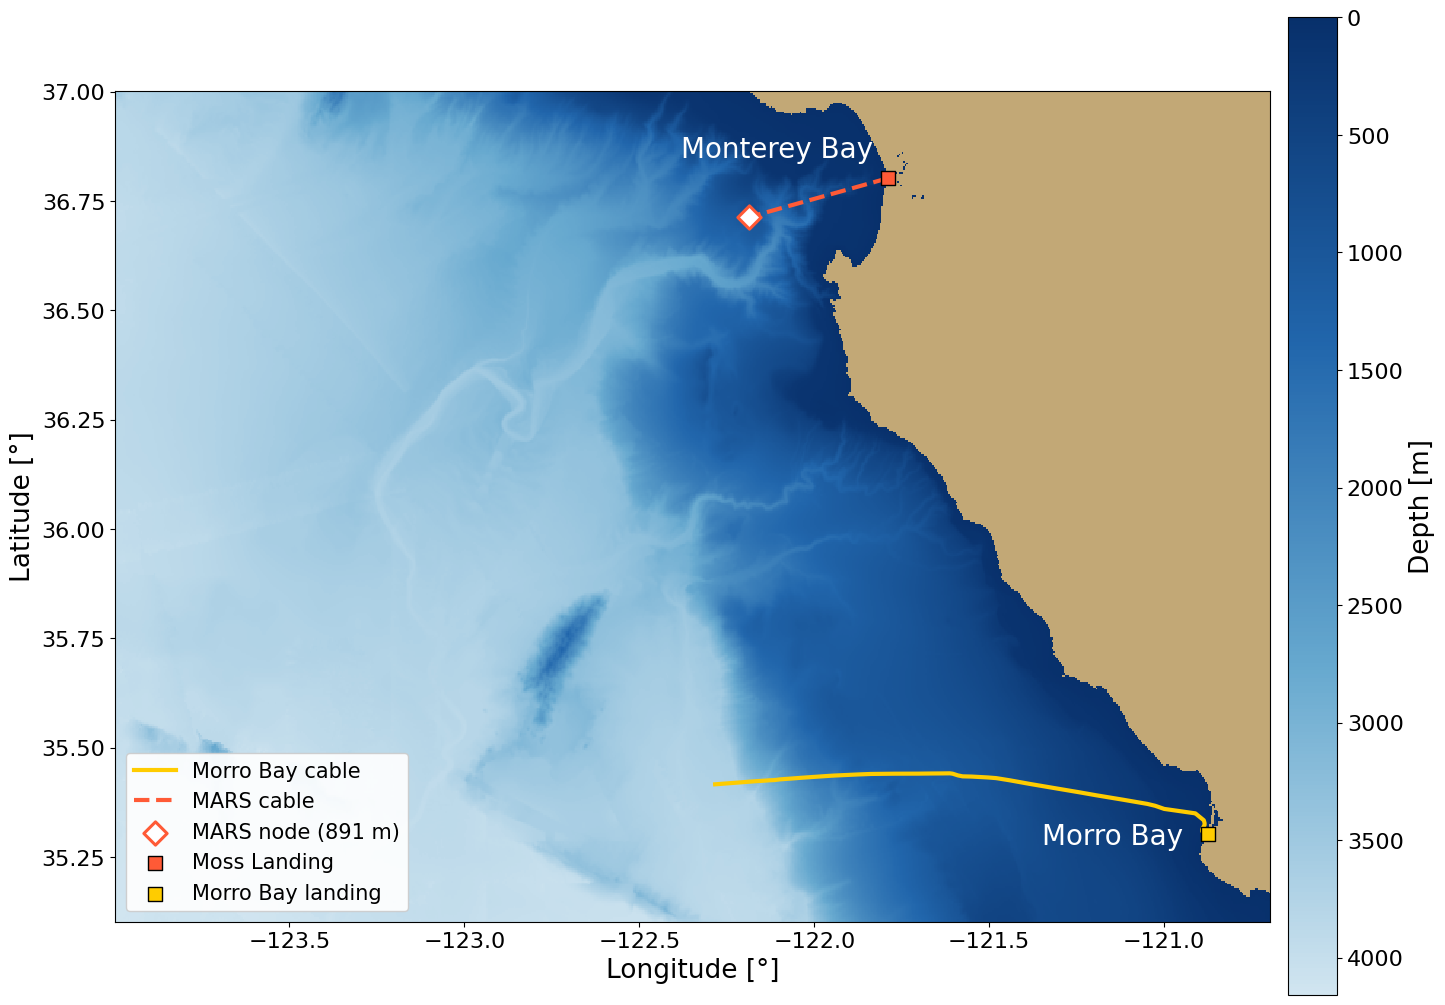

In [32]:
plt.rcParams.update({'font.size': 25})

lon_z, lat_z, Zz = load_bathy(DATADIR / "bathymetry_mars_morrobay_zoom_15s.csv")

fig, ax = plt.subplots(figsize=(15, 12))
plot_bathy(ax, lon_z, lat_z, Zz, fig)

ax.plot(mb_lon, mb_lat, color="#ffcc00", lw=3, label="Morro Bay cable")
ax.plot(mars_lon, mars_lat, color="#ff5a36", lw=3, ls="--", label="MARS cable")

ax.scatter(*mars_node, marker="D", s=140, color="white", edgecolor="#ff5a36", lw=2.2, zorder=5, label="MARS node (891 m)")
ax.scatter(mars_lon[0], mars_lat[0], marker="s", s=100, color="#ff5a36", edgecolor="k", zorder=5, label="Moss Landing")
ax.scatter(mb_lon[0], mb_lat[0], marker="s", s=100, color="#ffcc00", edgecolor="k", zorder=5, label="Morro Bay landing")

# ax.annotate("MARS node", mars_node, textcoords="offset points", xytext=(12, -16), color="white")
# ax.annotate("Moss Landing (MBARI)", (mars_lon[0], mars_lat[0]), textcoords="offset points",
#             xytext=(12, -4), color="white")
ax.annotate("Morro Bay", (-121.35, 35.28), color="white", fontsize=20)
ax.annotate("Monterey Bay", (-122.38, 36.85), color="white", fontsize=20)
# ax.annotate("Morro Bay\n(region)", (-121.55, 35.62), color="white", fontsize=15, ha="center")

ax.set_xlim(lon_z.min(), lon_z.max())
ax.set_ylim(lat_z.min(), lat_z.max())
ax.set_xlabel("Longitude [°]")
ax.set_ylabel("Latitude [°]")
ax.legend(loc="lower left", framealpha=0.92)
ax.set_aspect(1.25)
plt.tight_layout()
plt.savefig(FIGDIR / "22_mars_morrobay_zoom.png", dpi=150, bbox_inches="tight")
plt.show()